# ENCS5141 – Intelligent Systems Lab
## Assignment 1: Data Preprocessing, Feature Engineering, and Classification


**Dataset:** Heart Disease Dataset (`HeartDataSet.csv`)

### ***Sara Ewaida - 1203048***
---

## Table of Contents
1. [Import Libraries](#1)
2. [Load & Explore the Dataset](#2)
3. [Data Cleaning](#3)
4. [Feature Engineering](#4)
5. [Class Imbalance Handling](#5)
6. [Part 1 Evaluation – Raw vs Preprocessed](#6)
7. [Part 2 – Comparative Model Analysis](#7)
8. [Summary & Conclusion](#8)

---
<a id='1'></a>
## 1. Import Libraries

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import VarianceThreshold, SelectKBest, chi2, f_classif
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)
from imblearn.over_sampling import SMOTE

# Plotting style
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 100
print('Libraries loaded successfully.')

Libraries loaded successfully.


---
<a id='2'></a>
## 2. Load & Explore the Dataset

We begin with a thorough Exploratory Data Analysis (EDA) to understand the structure, types, distributions, and potential issues in the data before any cleaning is applied.

In [6]:
df_raw = pd.read_csv('HeartDataSet.csv')
print(f'Dataset shape: {df_raw.shape}')
df_raw.head(10)

Dataset shape: (918, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172.0,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156.0,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98.0,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108.0,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122.0,N,0.0,Up,0
5,39,M,NAP,120,339,0,Normal,170.0,N,0.0,Up,0
6,45,X,ATA,130,237,0,Normal,170.0,N,0.0,Up,0
7,54,M,NaN,110,208,0,Normal,142.0,N,0.0,Up,0
8,37,M,ASY,140,207,0,Normal,130.0,Y,1.5,Flat,1
9,48,F,ATA,120,284,0,Normal,120.0,N,0.0,Up,0


In [7]:
print('=== Data Types & Non-Null Counts ===')
df_raw.info()

=== Data Types & Non-Null Counts ===
<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   838 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           869 non-null    float64
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(2), int64(5), str(5)
memory usage: 97.5 KB


In [8]:
print('=== Descriptive Statistics (Numerical Features) ===')
df_raw.describe().round(2)

=== Descriptive Statistics (Numerical Features) ===


,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.00,918.00,918.00,918.00,869.00,918.00,918.00
mean,53.51,132.40,198.80,0.23,136.61,0.96,0.55
std,9.43,18.51,109.38,0.42,25.24,1.37,0.50
min,28.00,0.00,0.00,0.00,60.00,-2.60,0.00
25%,47.00,120.00,173.25,0.00,120.00,0.00,0.00
50%,54.00,130.00,223.00,0.00,138.00,0.60,1.00
75%,60.00,140.00,267.00,0.00,155.00,1.50,1.00
max,77.00,200.00,603.00,1.00,202.00,15.00,1.00


In [9]:
# ---------- Missing Values ----------
missing = df_raw.isnull().sum()
missing_pct = (missing / len(df_raw) * 100).round(2)
missing_df = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})
missing_df = missing_df[missing_df['Missing Count'] > 0]
print('=== Missing Values ===')
print(missing_df)

# ---------- Duplicates ----------
print(f'\nDuplicate rows: {df_raw.duplicated().sum()}')

=== Missing Values ===
               Missing Count  Missing %
ChestPainType             80       8.71
MaxHR                     49       5.34

Duplicate rows: 0


### 2.1 Categorical Feature Inspection

We examine the unique values of each categorical column to detect any noise or inconsistencies.

In [11]:
cat_cols = df_raw.select_dtypes(include='object').columns.tolist()
for col in cat_cols:
    print(f'{col}: {df_raw[col].value_counts().to_dict()}')

Sex: {'M': 717, 'F': 191, 'X': 2, 'Z': 1, 'G': 1, 'R': 1, 'S': 1, 'D': 1, 'E': 1, 'W': 1, 'V': 1}
ChestPainType: {'ASY': 456, 'NAP': 186, 'ATA': 155, 'TA': 41}
RestingECG: {'Normal': 552, 'LVH': 188, 'ST': 178}
ExerciseAngina: {'N': 547, 'Y': 371}
ST_Slope: {'Flat': 460, 'Up': 395, 'Down': 63}


**Finding 1 – Noisy `Sex` values:** The valid values for `Sex` are `M` and `F`. However, 10 records contain invalid single-letter codes (`X`, `Z`, `G`, `R`, `S`, `D`, `E`, `W`, `V`). These are data entry errors and will be treated as missing values.

### 2.2 Numerical Feature Inspection

In [14]:
print(f'Zero Cholesterol values : {(df_raw["Cholesterol"] == 0).sum()}')
print(f'Zero RestingBP values   : {(df_raw["RestingBP"] == 0).sum()}')
print(f'Cholesterol range       : {df_raw["Cholesterol"].min()} – {df_raw["Cholesterol"].max()}')
print(f'RestingBP range         : {df_raw["RestingBP"].min()} – {df_raw["RestingBP"].max()}')
print(f'Oldpeak range           : {df_raw["Oldpeak"].min()} – {df_raw["Oldpeak"].max()}')
print(f'MaxHR range             : {df_raw["MaxHR"].min()} – {df_raw["MaxHR"].max()}')

Zero Cholesterol values : 172
Zero RestingBP values   : 1
Cholesterol range       : 0 – 603
RestingBP range         : 0 – 200
Oldpeak range           : -2.6 – 15.0
MaxHR range             : 60.0 – 202.0


**Finding 2 – Impossible zeros in `Cholesterol`:** 172 records have Cholesterol = 0, which is medically impossible. These are likely missing values encoded as zero.

**Finding 3 – Zero `RestingBP`:** 1 record has RestingBP = 0, physiologically impossible.

**Finding 4 – Extreme `Oldpeak`:** Maximum value of 15 is unusually high (typical clinical range ≤ 6.2). This is a potential outlier.

### 2.3 Target Variable Distribution

HeartDisease distribution:
  0 (No Disease): 410 (44.7%)
  1 (Disease)   : 508 (55.3%)


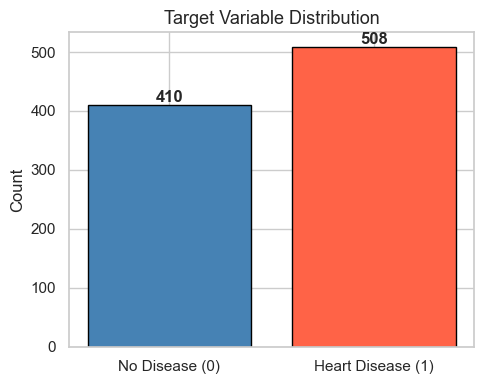

In [17]:
counts = df_raw['HeartDisease'].value_counts()
print('HeartDisease distribution:')
print(f'  0 (No Disease): {counts[0]} ({counts[0]/len(df_raw)*100:.1f}%)')
print(f'  1 (Disease)   : {counts[1]} ({counts[1]/len(df_raw)*100:.1f}%)')

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(['No Disease (0)', 'Heart Disease (1)'], [counts[0], counts[1]],
       color=['steelblue', 'tomato'], edgecolor='black')
ax.set_title('Target Variable Distribution', fontsize=13)
ax.set_ylabel('Count')
for i, v in enumerate([counts[0], counts[1]]):
    ax.text(i, v + 5, str(v), ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

**Finding 5 – Mild Class Imbalance:** 508 (55.3%) vs 410 (44.7%). While not severe, SMOTE will be applied to ensure the model is not biased.

### 2.4 Raw Feature Distributions

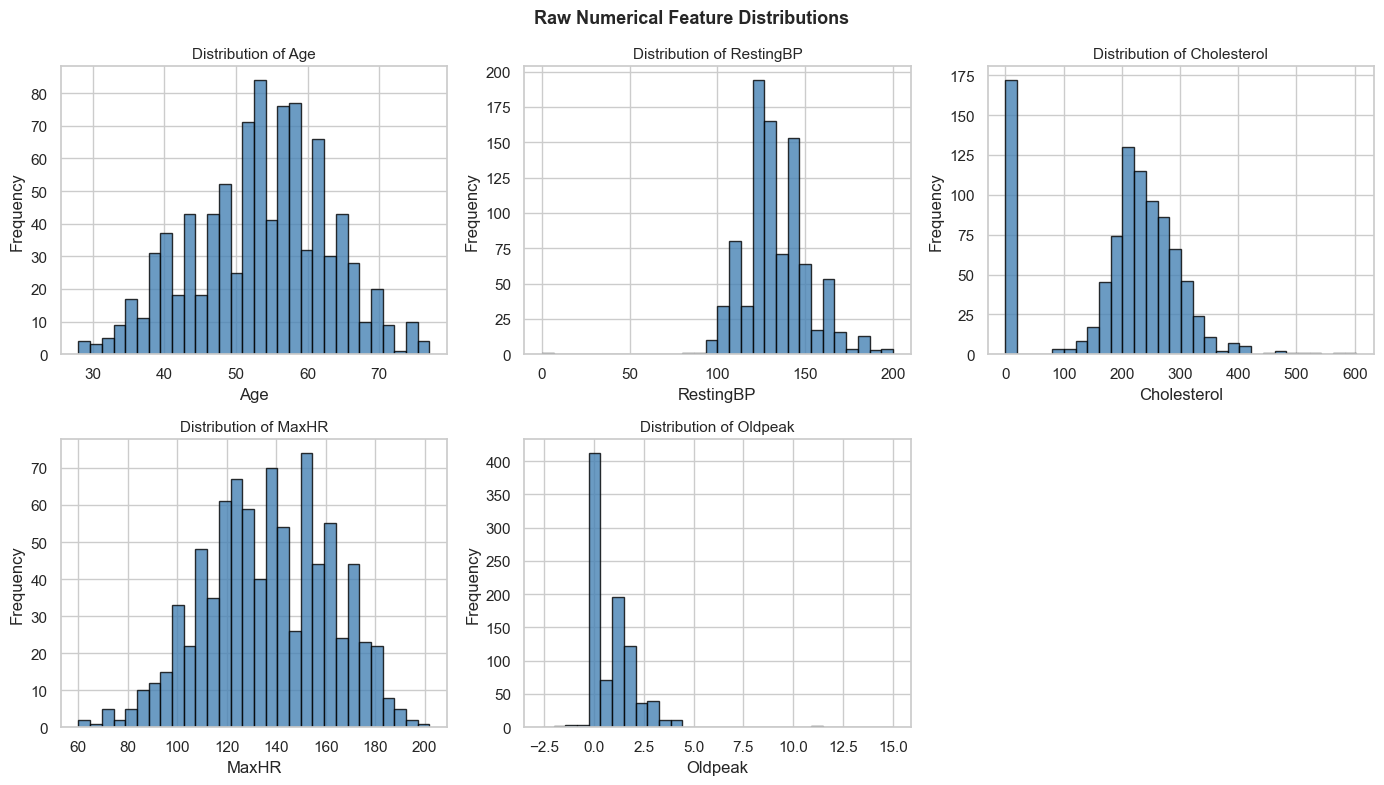

In [20]:
num_cols = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()
for i, col in enumerate(num_cols):
    axes[i].hist(df_raw[col].dropna(), bins=30, color='steelblue', edgecolor='black', alpha=0.8)
    axes[i].set_title(f'Distribution of {col}', fontsize=11)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frequency')
axes[5].axis('off')
plt.suptitle('Raw Numerical Feature Distributions', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

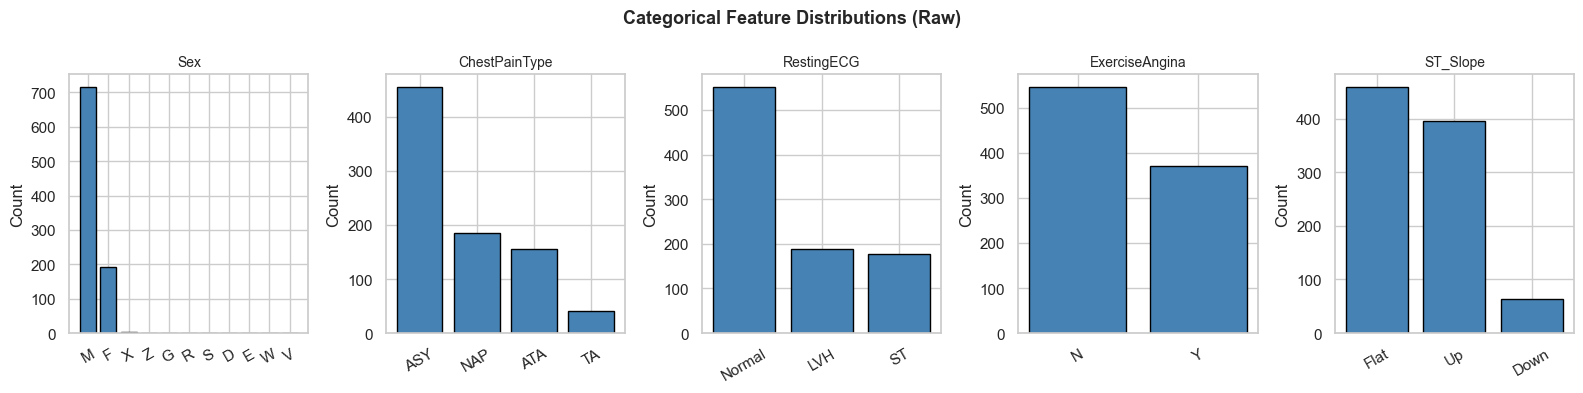

In [21]:
# Categorical feature distributions
fig, axes = plt.subplots(1, len(cat_cols), figsize=(16, 4))
for ax, col in zip(axes, cat_cols):
    vc = df_raw[col].value_counts()
    ax.bar(vc.index, vc.values, color='steelblue', edgecolor='black')
    ax.set_title(col, fontsize=10)
    ax.set_ylabel('Count')
    ax.tick_params(axis='x', rotation=30)
plt.suptitle('Categorical Feature Distributions (Raw)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

### 2.5 Correlation Heatmap (Raw Numerical Features)

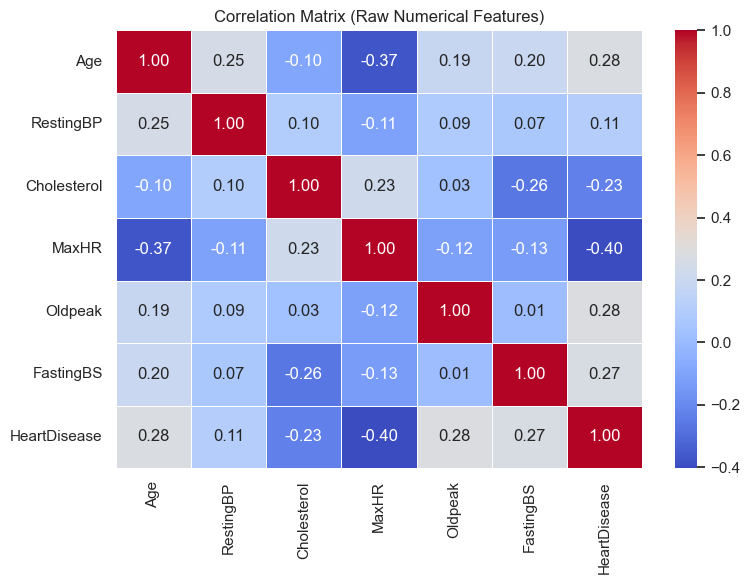

In [23]:
fig, ax = plt.subplots(figsize=(8, 6))
corr_raw = df_raw[num_cols + ['FastingBS', 'HeartDisease']].corr()
sns.heatmap(corr_raw, annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5, ax=ax)
ax.set_title('Correlation Matrix (Raw Numerical Features)', fontsize=12)
plt.tight_layout()
plt.show()

### 2.6 Feature vs Target Relationship (Box Plots)

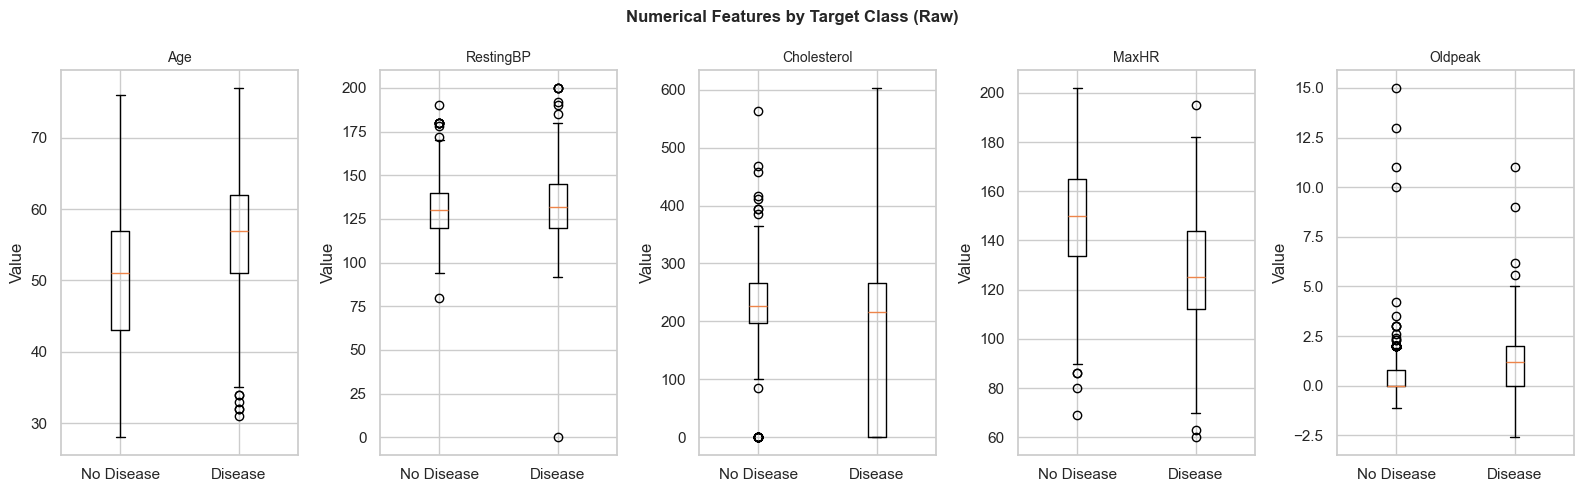

In [25]:
fig, axes = plt.subplots(1, len(num_cols), figsize=(16, 5))
for ax, col in zip(axes, num_cols):
    groups = [df_raw[df_raw['HeartDisease'] == 0][col].dropna(),
              df_raw[df_raw['HeartDisease'] == 1][col].dropna()]
    ax.boxplot(groups, labels=['No Disease', 'Disease'])
    ax.set_title(col, fontsize=10)
    ax.set_ylabel('Value')
plt.suptitle('Numerical Features by Target Class (Raw)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

---
<a id='3'></a>
## 3. Data Cleaning

Based on the EDA findings, we apply the following cleaning steps:

| # | Issue | Technique |
|---|-------|-----------|
| 1 | Noisy `Sex` values (10 records) | Replace invalid codes with `NaN`, impute by **mode** |
| 2 | Missing `ChestPainType` (80) | Impute by **mode** (most frequent category) |
| 3 | Missing `MaxHR` (49) | Impute by **median** (robust to outliers) |
| 4 | Zero `Cholesterol` (172) | Replace 0 → `NaN`, impute by **median** of non-zero values |
| 5 | Zero `RestingBP` (1) | Replace 0 → `NaN`, impute by **median** |
| 6 | Outliers in numerical features | **IQR capping** (Winsorization) |

In [27]:
df = df_raw.copy()

# Step 1: Fix noisy Sex values
valid_sex = {'M', 'F'}
df['Sex'] = df['Sex'].apply(lambda x: x if x in valid_sex else np.nan)
print(f"Sex after fixing: {df['Sex'].value_counts().to_dict()}")
print(f"Sex NaN count: {df['Sex'].isnull().sum()}")

Sex after fixing: {'M': 717, 'F': 191}
Sex NaN count: 10


In [28]:
# Step 2: Replace impossible zeros with NaN
df['Cholesterol'] = df['Cholesterol'].replace(0, np.nan)
df['RestingBP'] = df['RestingBP'].replace(0, np.nan)
print(f'Cholesterol NaN: {df["Cholesterol"].isnull().sum()}')
print(f'RestingBP NaN  : {df["RestingBP"].isnull().sum()}')

Cholesterol NaN: 172
RestingBP NaN  : 1


In [29]:
# Step 3: Impute all missing values
# Categorical → mode
for col in ['Sex', 'ChestPainType']:
    mode_val = df[col].mode()[0]
    df[col] = df[col].fillna(mode_val)
    print(f'{col} imputed with mode: "{mode_val}"')

# Numerical → median
for col in ['MaxHR', 'Cholesterol', 'RestingBP']:
    median_val = df[col].median()
    df[col] = df[col].fillna(median_val)
    print(f'{col} imputed with median: {median_val:.2f}')

print(f'\nRemaining missing values: {df.isnull().sum().sum()}')

Sex imputed with mode: "M"
ChestPainType imputed with mode: "ASY"
MaxHR imputed with median: 138.00
Cholesterol imputed with median: 237.00
RestingBP imputed with median: 130.00

Remaining missing values: 0


### 3.1 Outlier Detection & Handling (IQR Capping / Winsorization)

We use the IQR method to detect outliers and **cap** (Winsorize) them at the 1.5×IQR fence, rather than removing rows. Capping preserves all data while neutralizing extreme values. This is especially important here because of the Oldpeak = 15 anomaly and high Cholesterol values.

In [31]:
def detect_outliers_iqr(data, col):
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = ((data[col] < lower) | (data[col] > upper)).sum()
    return Q1, Q3, IQR, lower, upper, outliers

print(f'{"Feature":<15} {"Q1":>8} {"Q3":>8} {"IQR":>8} {"Lower":>8} {"Upper":>8} {"Outliers":>10}')
print('-' * 70)
num_features = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']
for col in num_features:
    Q1, Q3, IQR, lower, upper, n_out = detect_outliers_iqr(df, col)
    print(f'{col:<15} {Q1:>8.2f} {Q3:>8.2f} {IQR:>8.2f} {lower:>8.2f} {upper:>8.2f} {n_out:>10}')

Feature               Q1       Q3      IQR    Lower    Upper   Outliers
----------------------------------------------------------------------
Age                47.00    60.00    13.00    27.50    79.50          0
RestingBP         120.00   140.00    20.00    90.00   170.00         27
Cholesterol       214.00   267.00    53.00   134.50   346.50         41
MaxHR             120.00   154.00    34.00    69.00   205.00          2
Oldpeak             0.00     1.50     1.50    -2.25     3.75         22


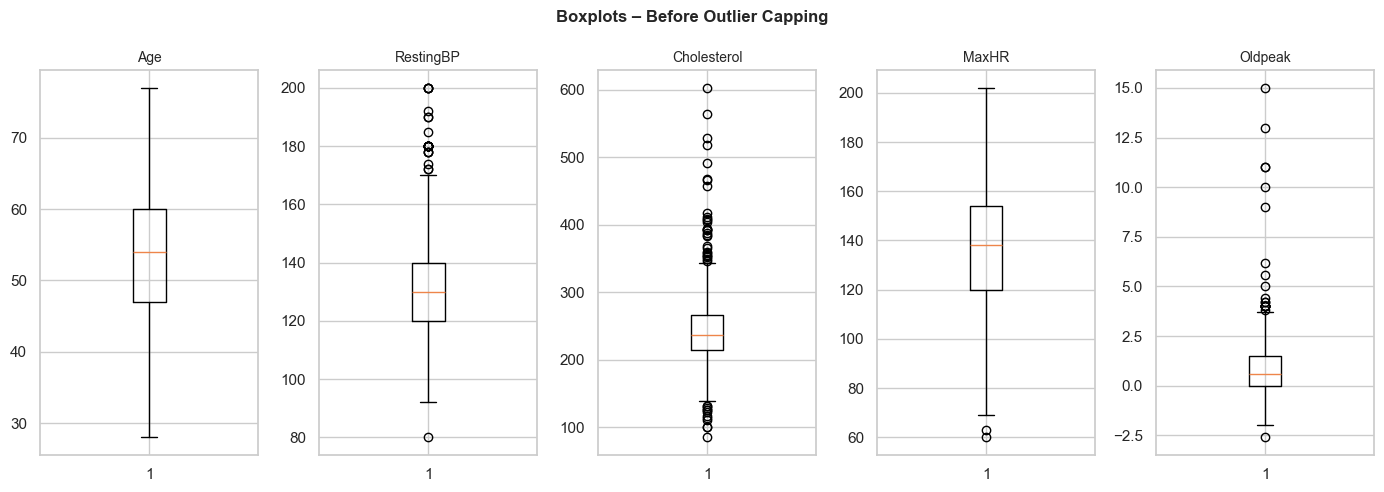

In [32]:
# Visualise outliers using boxplots before capping
fig, axes = plt.subplots(1, len(num_features), figsize=(14, 5))
for ax, col in zip(axes, num_features):
    ax.boxplot(df[col].dropna())
    ax.set_title(col, fontsize=10)
plt.suptitle('Boxplots – Before Outlier Capping', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

In [33]:
# Apply IQR Capping (Winsorization)
df_clean = df.copy()
for col in num_features:
    Q1, Q3, IQR, lower, upper, _ = detect_outliers_iqr(df_clean, col)
    df_clean[col] = df_clean[col].clip(lower=lower, upper=upper)

# Verify no more outliers
print('Outlier count after capping:')
for col in num_features:
    _, _, _, _, _, n_out = detect_outliers_iqr(df_clean, col)
    print(f'  {col}: {n_out}')

Outlier count after capping:
  Age: 0
  RestingBP: 0
  Cholesterol: 0
  MaxHR: 0
  Oldpeak: 0


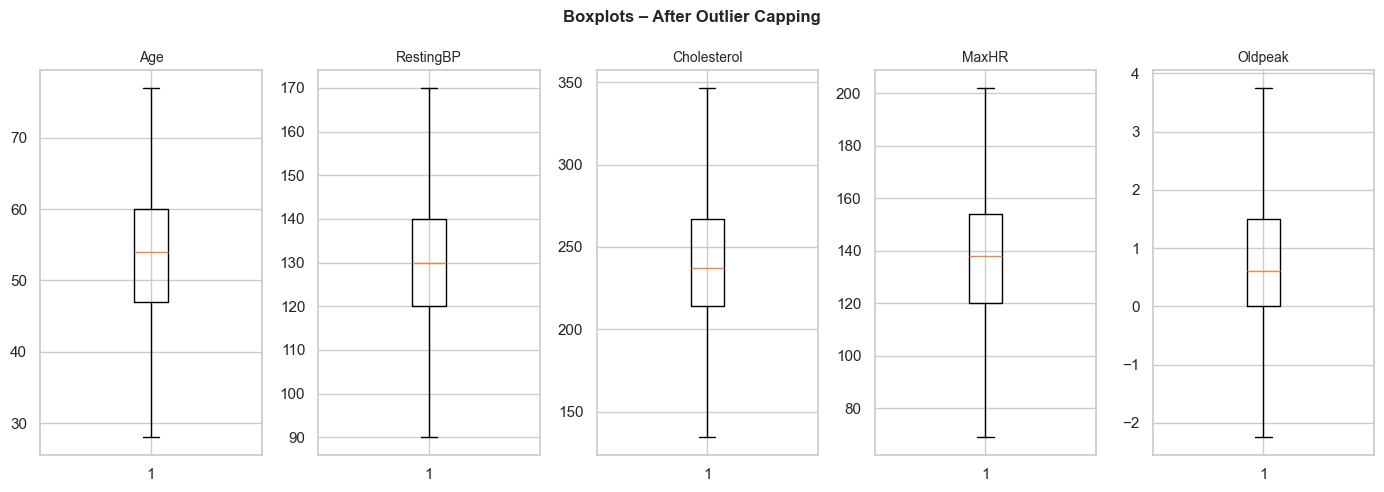

In [34]:
# Boxplots after capping
fig, axes = plt.subplots(1, len(num_features), figsize=(14, 5))
for ax, col in zip(axes, num_features):
    ax.boxplot(df_clean[col])
    ax.set_title(col, fontsize=10)
plt.suptitle('Boxplots – After Outlier Capping', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

---
<a id='4'></a>
## 4. Feature Engineering

### 4.1 Encoding Categorical Variables

- **Binary categories** (`Sex`, `ExerciseAngina`): Label Encoding (0/1) — no ordering implied, and these are genuinely binary.
- **Multi-class nominal categories** (`ChestPainType`, `RestingECG`, `ST_Slope`): One-Hot Encoding — prevents the model from assuming any ordinal relationship between classes.

In [36]:
df_enc = df_clean.copy()

# Binary encoding
le = LabelEncoder()
df_enc['Sex'] = le.fit_transform(df_enc['Sex'])          # M=1, F=0
df_enc['ExerciseAngina'] = le.fit_transform(df_enc['ExerciseAngina'])  # Y=1, N=0

# One-Hot Encoding
ohe_cols = ['ChestPainType', 'RestingECG', 'ST_Slope']
df_enc = pd.get_dummies(df_enc, columns=ohe_cols, drop_first=False)

print(f'Shape after encoding: {df_enc.shape}')
print('Columns:', list(df_enc.columns))

Shape after encoding: (918, 19)
Columns: ['Age', 'Sex', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'HeartDisease', 'ChestPainType_ASY', 'ChestPainType_ATA', 'ChestPainType_NAP', 'ChestPainType_TA', 'RestingECG_LVH', 'RestingECG_Normal', 'RestingECG_ST', 'ST_Slope_Down', 'ST_Slope_Flat', 'ST_Slope_Up']


### 4.2 Feature Scaling (Standardization)

We apply **StandardScaler** (z-score normalization) to numerical features. This is essential for SVM and MLP which are sensitive to feature scale, and also benefits PCA.

In [38]:
X = df_enc.drop('HeartDisease', axis=1)
y = df_enc['HeartDisease']

# Identify numerical columns to scale
num_scale_cols = ['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak']

scaler = StandardScaler()
X_scaled = X.copy()
X_scaled[num_scale_cols] = scaler.fit_transform(X[num_scale_cols])

print('Scaling applied to:', num_scale_cols)
print(X_scaled[num_scale_cols].describe().round(2))

Scaling applied to: ['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak']
          Age  RestingBP  Cholesterol  FastingBS   MaxHR  Oldpeak
count  918.00     918.00       918.00     918.00  918.00   918.00
mean    -0.00      -0.00        -0.00      -0.00    0.00     0.00
std      1.00       1.00         1.00       1.00    1.00     1.00
min     -2.71      -2.49        -2.37      -0.55   -2.76    -2.99
25%     -0.69      -0.72        -0.60      -0.55   -0.68    -0.85
50%      0.05      -0.13        -0.09      -0.55    0.05    -0.29
75%      0.69       0.46         0.57      -0.55    0.71     0.57
max      2.49       2.23         2.34       1.81    2.66     2.70


### 4.3 Feature Selection

#### (a) Variance Threshold (Filter Method)
Remove features with near-zero variance — they carry no discriminative information.

In [40]:
sel = VarianceThreshold(threshold=0.01)
sel.fit(X_scaled)
low_var = X_scaled.columns[~sel.get_support()].tolist()
print(f'Features removed by VarianceThreshold (threshold=0.01): {low_var}')
print(f'Features retained: {sel.get_support().sum()} / {X_scaled.shape[1]}')

Features removed by VarianceThreshold (threshold=0.01): []
Features retained: 18 / 18


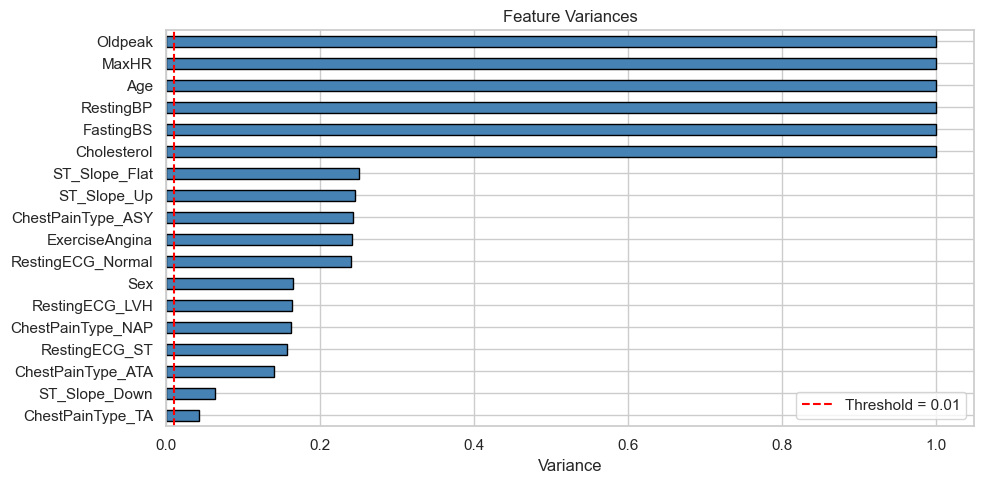

In [41]:
# Variance of each feature
var_series = pd.Series(sel.variances_, index=X_scaled.columns).sort_values()
fig, ax = plt.subplots(figsize=(10, 5))
var_series.plot(kind='barh', ax=ax, color='steelblue', edgecolor='black')
ax.axvline(x=0.01, color='red', linestyle='--', label='Threshold = 0.01')
ax.set_title('Feature Variances', fontsize=12)
ax.set_xlabel('Variance')
ax.legend()
plt.tight_layout()
plt.show()

#### (b) Correlation-based Feature Selection (Filter Method)

Highly correlated features are redundant. We remove one feature from any pair with |r| > 0.85.

Features to drop due to high correlation (>0.85): ['ST_Slope_Up']
Features remaining after correlation filter: 17


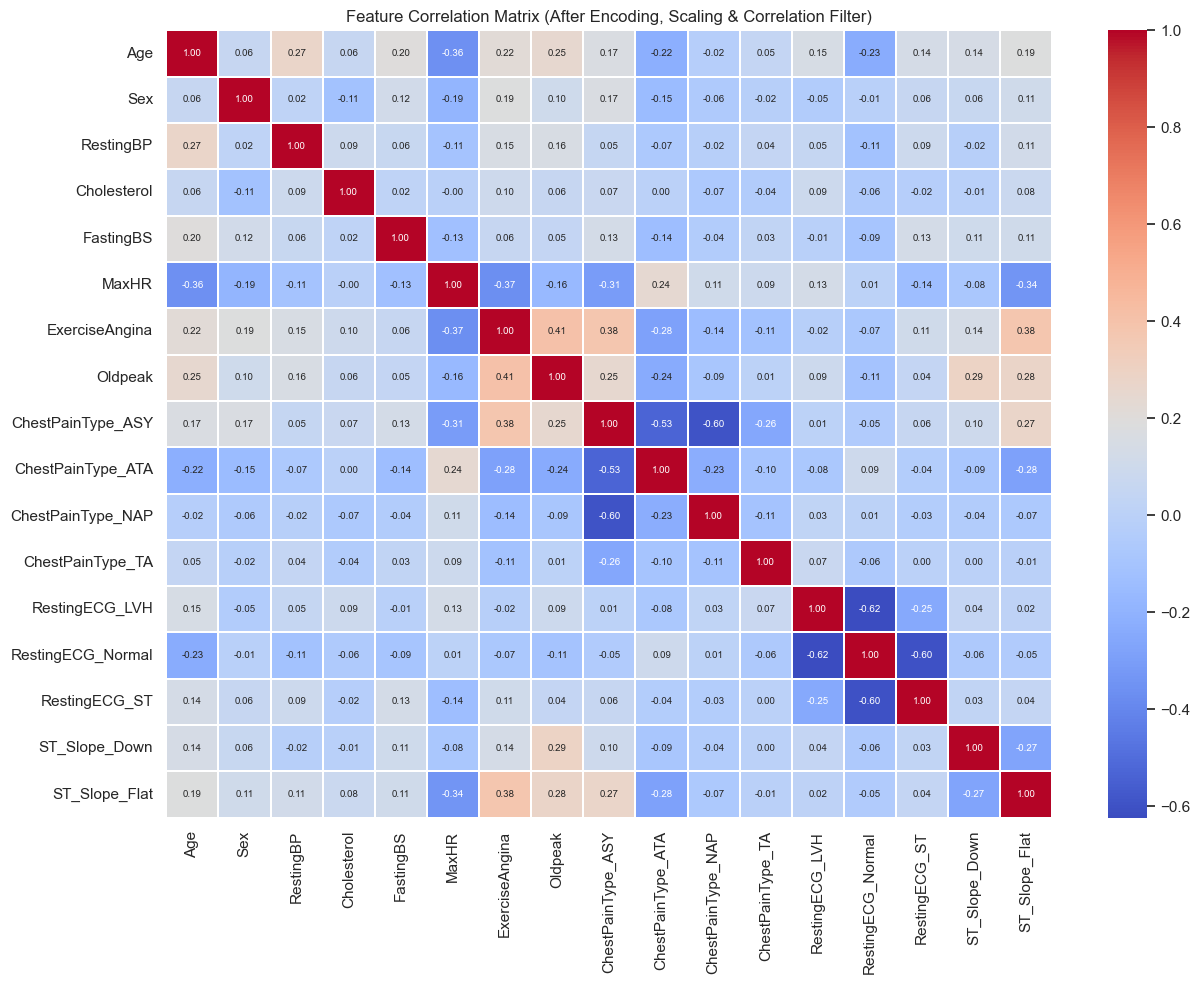

In [43]:
corr_matrix = X_scaled.corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop_corr = [col for col in upper.columns if any(upper[col] > 0.85)]
print(f'Features to drop due to high correlation (>0.85): {to_drop_corr}')

# Actually drop them from X_scaled
X_scaled_filtered = X_scaled.drop(columns=to_drop_corr)
print(f'Features remaining after correlation filter: {X_scaled_filtered.shape[1]}')

# Heatmap (on filtered features)
fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(X_scaled_filtered.corr(), annot=True, fmt='.2f', cmap='coolwarm',
            linewidths=0.3, ax=ax, annot_kws={'size': 7})
ax.set_title('Feature Correlation Matrix (After Encoding, Scaling & Correlation Filter)', fontsize=12)
plt.tight_layout()
plt.show()

#### (c) Feature Importance (Embedded Method – Random Forest)

Random Forest provides an embedded feature importance score based on mean decrease in impurity (Gini). We use this to confirm which features contribute most.

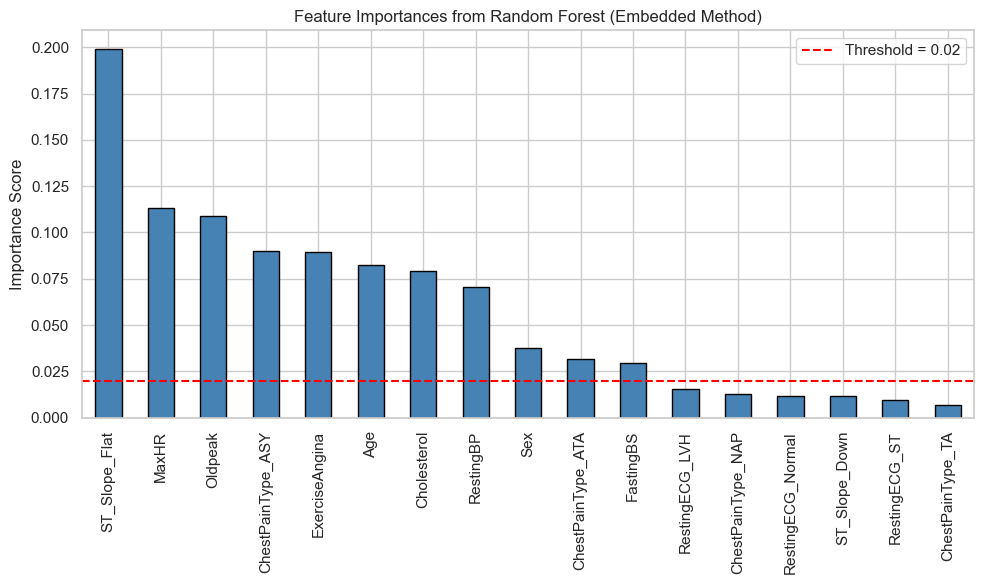

Top 10 features:
ST_Slope_Flat        0.1992
MaxHR                0.1134
Oldpeak              0.1091
ChestPainType_ASY    0.0898
ExerciseAngina       0.0896
Age                  0.0826
Cholesterol          0.0793
RestingBP            0.0706
Sex                  0.0375
ChestPainType_ATA    0.0315
dtype: float64


In [45]:
rf_imp = RandomForestClassifier(n_estimators=100, random_state=42)
rf_imp.fit(X_scaled_filtered, y)
importances = pd.Series(rf_imp.feature_importances_, index=X_scaled_filtered.columns).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))
importances.plot(kind='bar', ax=ax, color='steelblue', edgecolor='black')
ax.set_title('Feature Importances from Random Forest (Embedded Method)', fontsize=12)
ax.set_ylabel('Importance Score')
ax.axhline(y=0.02, color='red', linestyle='--', label='Threshold = 0.02')
ax.legend()
plt.tight_layout()
plt.show()

print('Top 10 features:')
print(importances.head(10).round(4))

In [46]:
# Select features with importance >= 0.02
selected_features = importances[importances >= 0.02].index.tolist()
print(f'Selected {len(selected_features)} features: {selected_features}')
X_selected = X_scaled_filtered[selected_features].copy()

Selected 11 features: ['ST_Slope_Flat', 'MaxHR', 'Oldpeak', 'ChestPainType_ASY', 'ExerciseAngina', 'Age', 'Cholesterol', 'RestingBP', 'Sex', 'ChestPainType_ATA', 'FastingBS']


### 4.4 Dimensionality Reduction (PCA)

PCA (Principal Component Analysis) is applied to understand how much variance can be explained with fewer components. It is an **unsupervised** linear transformation technique. We retain enough components to explain ≥ 95% of variance.

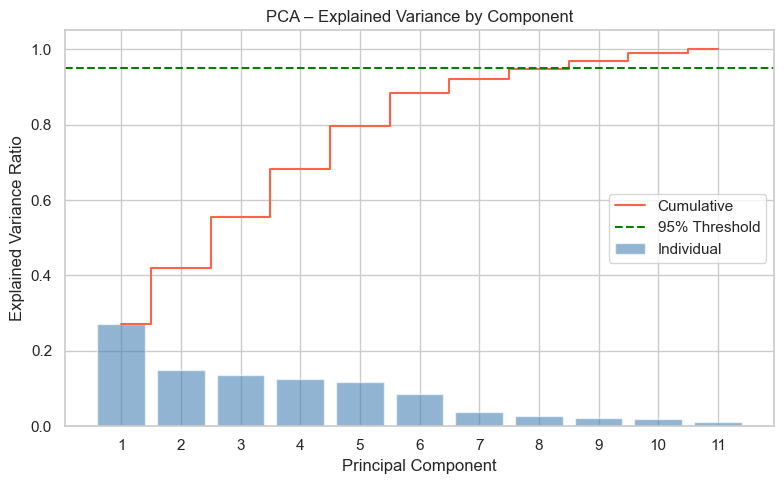

Components needed to explain 95% variance: 9


In [48]:
pca_explorer = PCA(random_state=42)
pca_explorer.fit(X_selected)
explained = pca_explorer.explained_variance_ratio_
cumulative = np.cumsum(explained)

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(range(1, len(explained)+1), explained, alpha=0.6, color='steelblue', label='Individual')
ax.step(range(1, len(cumulative)+1), cumulative, where='mid', color='tomato', label='Cumulative')
ax.axhline(y=0.95, color='green', linestyle='--', label='95% Threshold')
ax.set_xlabel('Principal Component')
ax.set_ylabel('Explained Variance Ratio')
ax.set_title('PCA – Explained Variance by Component', fontsize=12)
ax.legend()
ax.set_xticks(range(1, len(explained)+1))
plt.tight_layout()
plt.show()

n95 = np.searchsorted(cumulative, 0.95) + 1
print(f'Components needed to explain 95% variance: {n95}')

In [49]:
# Apply PCA keeping 95% variance
pca = PCA(n_components=0.95, random_state=42)
X_pca = pca.fit_transform(X_selected)
print(f'Shape before PCA: {X_selected.shape}')
print(f'Shape after  PCA: {X_pca.shape}')
print(f'Variance retained: {pca.explained_variance_ratio_.sum()*100:.1f}%')

Shape before PCA: (918, 11)
Shape after  PCA: (918, 9)
Variance retained: 97.0%


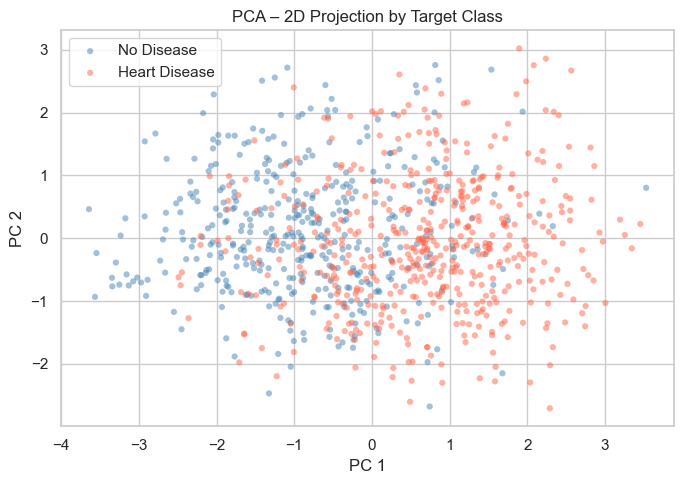

In [50]:
# 2D PCA scatter for visualization
pca2d = PCA(n_components=2, random_state=42)
X_2d = pca2d.fit_transform(X_selected)
fig, ax = plt.subplots(figsize=(7, 5))
colors = ['steelblue', 'tomato']
for cls, color, label in zip([0, 1], colors, ['No Disease', 'Heart Disease']):
    mask = y == cls
    ax.scatter(X_2d[mask, 0], X_2d[mask, 1], c=color, label=label,
               alpha=0.5, edgecolors='none', s=20)
ax.set_xlabel('PC 1')
ax.set_ylabel('PC 2')
ax.set_title('PCA – 2D Projection by Target Class', fontsize=12)
ax.legend()
plt.tight_layout()
plt.show()

---
<a id='5'></a>
## 5. Class Imbalance Handling (SMOTE)

**SMOTE** (Synthetic Minority Over-sampling Technique) generates synthetic samples for the minority class by interpolating between existing minority samples. It is applied **only on the training set** after the train/test split to prevent data leakage.

In [52]:
# ---- Final preprocessed dataset (selected features, no PCA for model training) ----
# PCA is used for visualization; for model training we keep selected features
X_final = X_selected.copy()
y_final = y.copy()

# Train/Test split (80/20, stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X_final, y_final, test_size=0.2, random_state=42, stratify=y_final
)

print(f'Train size: {X_train.shape[0]}  |  Test size: {X_test.shape[0]}')
print(f'Train class distribution: {dict(y_train.value_counts())}')
print(f'Test  class distribution: {dict(y_test.value_counts())}')

Train size: 734  |  Test size: 184
Train class distribution: {1: np.int64(406), 0: np.int64(328)}
Test  class distribution: {1: np.int64(102), 0: np.int64(82)}


After SMOTE – Train class distribution: {1: np.int64(406), 0: np.int64(406)}


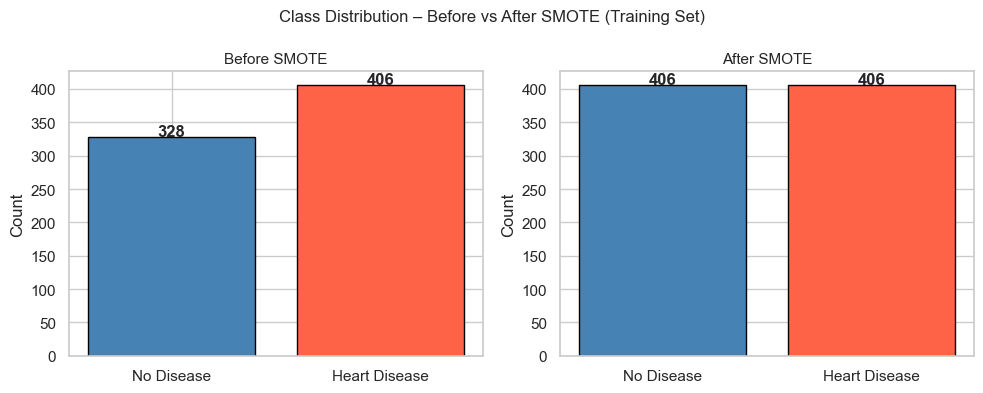

In [53]:
# Apply SMOTE only on training data
smote = SMOTE(random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

print(f'After SMOTE – Train class distribution: {dict(pd.Series(y_train_sm).value_counts())}')

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (data, title) in zip(axes, [(y_train, 'Before SMOTE'), (y_train_sm, 'After SMOTE')]):
    vc = pd.Series(data).value_counts()
    ax.bar(['No Disease', 'Heart Disease'], [vc[0], vc[1]],
           color=['steelblue', 'tomato'], edgecolor='black')
    ax.set_title(title, fontsize=11)
    ax.set_ylabel('Count')
    for i, v in enumerate([vc[0], vc[1]]):
        ax.text(i, v + 2, str(v), ha='center', fontweight='bold')
plt.suptitle('Class Distribution – Before vs After SMOTE (Training Set)', fontsize=12)
plt.tight_layout()
plt.show()

---
<a id='6'></a>
## 6. Part 1 Evaluation – Raw Data vs Preprocessed Data

We train a **Random Forest** classifier on both the raw and the fully preprocessed data to quantify the impact of our preprocessing pipeline.

In [55]:
def evaluate_model(model, X_tr, y_tr, X_te, y_te, label):
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)
    metrics = {
        'Accuracy' : accuracy_score(y_te, y_pred),
        'Precision': precision_score(y_te, y_pred, zero_division=0),
        'Recall'   : recall_score(y_te, y_pred, zero_division=0),
        'F1-Score' : f1_score(y_te, y_pred, zero_division=0),
    }
    print(f'\n--- {label} ---')
    for k, v in metrics.items():
        print(f'  {k:<12}: {v:.4f}')
    print('\nClassification Report:')
    print(classification_report(y_te, y_pred, target_names=['No Disease', 'Heart Disease']))
    return metrics, y_pred

In [56]:
# ---- RAW DATA ----
# Minimal preprocessing on raw data: only drop NaN rows & encode categoricals
df_raw_proc = df_raw.copy()
df_raw_proc['Sex'] = df_raw_proc['Sex'].apply(lambda x: x if x in {'M','F'} else np.nan)
df_raw_proc = df_raw_proc.dropna()
# basic label encode all categoricals
for col in ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']:
    df_raw_proc[col] = LabelEncoder().fit_transform(df_raw_proc[col].astype(str))

X_raw = df_raw_proc.drop('HeartDisease', axis=1)
y_raw = df_raw_proc['HeartDisease']
X_raw_tr, X_raw_te, y_raw_tr, y_raw_te = train_test_split(
    X_raw, y_raw, test_size=0.2, random_state=42, stratify=y_raw)

rf_raw = RandomForestClassifier(n_estimators=100, random_state=42)
metrics_raw, pred_raw = evaluate_model(rf_raw, X_raw_tr, y_raw_tr,
                                        X_raw_te, y_raw_te, 'Random Forest on RAW Data')


--- Random Forest on RAW Data ---
  Accuracy    : 0.8726
  Precision   : 0.8824
  Recall      : 0.8824
  F1-Score    : 0.8824

Classification Report:
               precision    recall  f1-score   support

   No Disease       0.86      0.86      0.86        72
Heart Disease       0.88      0.88      0.88        85

     accuracy                           0.87       157
    macro avg       0.87      0.87      0.87       157
 weighted avg       0.87      0.87      0.87       157



In [57]:
# ---- PREPROCESSED DATA ----
rf_pre = RandomForestClassifier(n_estimators=100, random_state=42)
metrics_pre, pred_pre = evaluate_model(rf_pre, X_train_sm, y_train_sm,
                                        X_test, y_test, 'Random Forest on PREPROCESSED Data')


--- Random Forest on PREPROCESSED Data ---
  Accuracy    : 0.8478
  Precision   : 0.8776
  Recall      : 0.8431
  F1-Score    : 0.8600

Classification Report:
               precision    recall  f1-score   support

   No Disease       0.81      0.85      0.83        82
Heart Disease       0.88      0.84      0.86       102

     accuracy                           0.85       184
    macro avg       0.85      0.85      0.85       184
 weighted avg       0.85      0.85      0.85       184




=== Performance Comparison: Raw vs Preprocessed ===
              Raw  Preprocessed
Accuracy   0.8726        0.8478
Precision  0.8824        0.8776
Recall     0.8824        0.8431
F1-Score   0.8824        0.8600


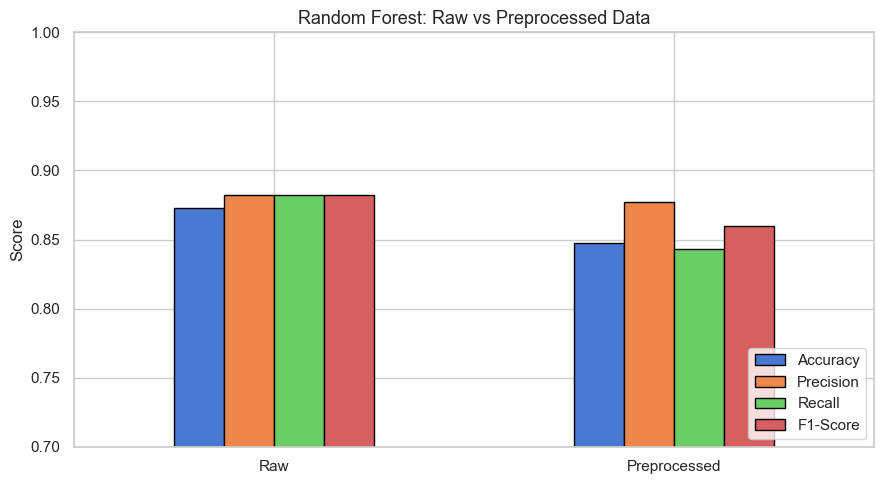

In [58]:
# ---- Comparison Table ----
comparison_df = pd.DataFrame({'Raw': metrics_raw, 'Preprocessed': metrics_pre})
print('\n=== Performance Comparison: Raw vs Preprocessed ===')
print(comparison_df.round(4))

# Bar chart
comparison_df.T.plot(kind='bar', figsize=(9, 5), edgecolor='black')
plt.title('Random Forest: Raw vs Preprocessed Data', fontsize=13)
plt.ylabel('Score')
plt.ylim(0.7, 1.0)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

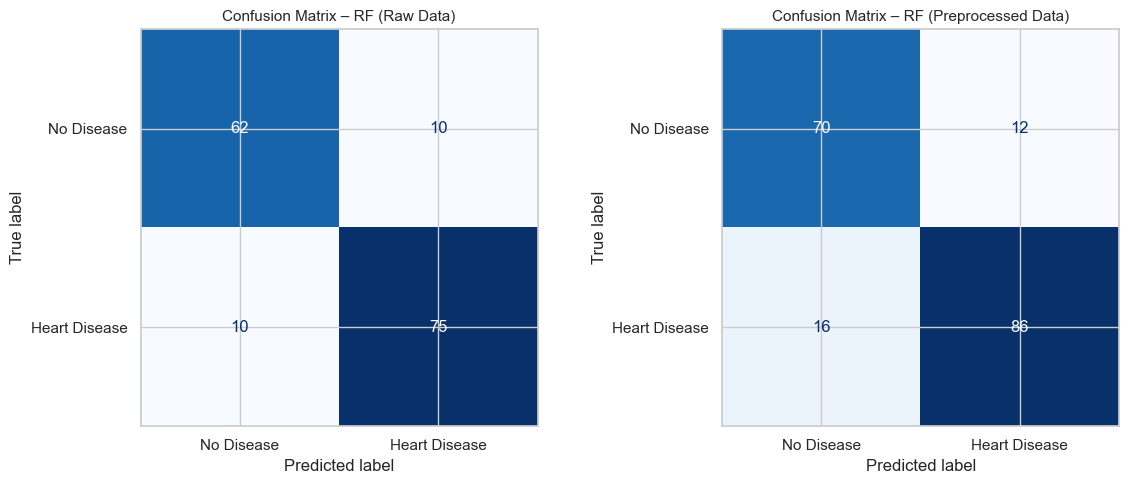

In [59]:
# Confusion Matrices side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, y_pred, title in zip(axes,
                              [pred_raw, pred_pre],
                              ['Raw Data', 'Preprocessed Data']):
    y_true = y_raw_te if title == 'Raw Data' else y_test
    cm = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(cm, display_labels=['No Disease', 'Heart Disease'])
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(f'Confusion Matrix – RF ({title})', fontsize=11)
plt.tight_layout()
plt.show()

---
<a id='7'></a>
## 7. Part 2 – Comparative Analysis of Classification Models

We compare three classifiers on the preprocessed (SMOTE-balanced) training data:
- **Random Forest (RF)**
- **Support Vector Machine (SVM)**
- **Multilayer Perceptron (MLP)**

### 7.1 Baseline Models (Default Hyperparameters)

In [61]:
models = {
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'SVM'          : SVC(kernel='rbf', random_state=42),
    'MLP'          : MLPClassifier(hidden_layer_sizes=(100, 50), max_iter=500, random_state=42),
}

results = {}
preds   = {}
for name, model in models.items():
    m, pred = evaluate_model(model, X_train_sm, y_train_sm, X_test, y_test, name)
    results[name] = m
    preds[name] = pred


--- Random Forest ---
  Accuracy    : 0.8478
  Precision   : 0.8776
  Recall      : 0.8431
  F1-Score    : 0.8600

Classification Report:
               precision    recall  f1-score   support

   No Disease       0.81      0.85      0.83        82
Heart Disease       0.88      0.84      0.86       102

     accuracy                           0.85       184
    macro avg       0.85      0.85      0.85       184
 weighted avg       0.85      0.85      0.85       184


--- SVM ---
  Accuracy    : 0.8696
  Precision   : 0.8750
  Recall      : 0.8922
  F1-Score    : 0.8835

Classification Report:
               precision    recall  f1-score   support

   No Disease       0.86      0.84      0.85        82
Heart Disease       0.88      0.89      0.88       102

     accuracy                           0.87       184
    macro avg       0.87      0.87      0.87       184
 weighted avg       0.87      0.87      0.87       184


--- MLP ---
  Accuracy    : 0.8152
  Precision   : 0.8333
  Recal


=== Baseline Model Comparison ===
               Accuracy  Precision  Recall  F1-Score
Random Forest    0.8478     0.8776  0.8431    0.8600
SVM              0.8696     0.8750  0.8922    0.8835
MLP              0.8152     0.8333  0.8333    0.8333


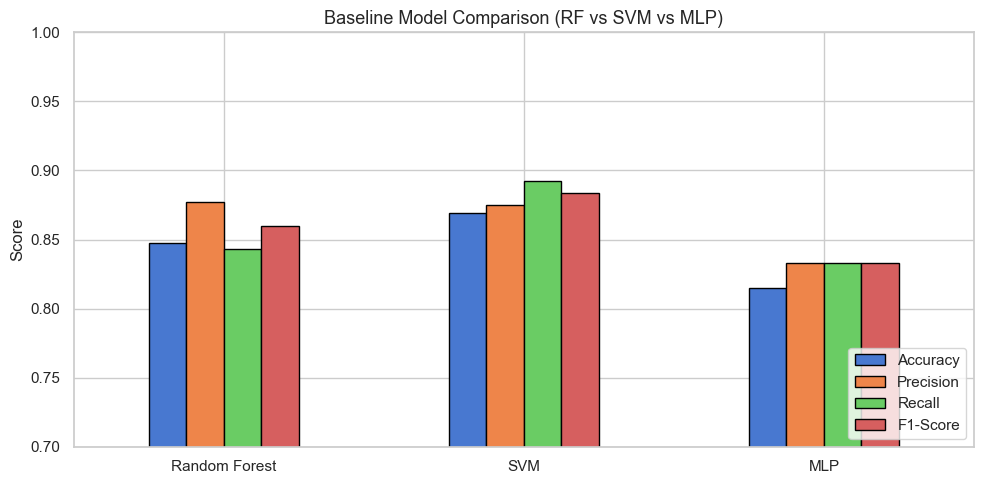

In [62]:
# Comparison Table
results_df = pd.DataFrame(results).T
print('\n=== Baseline Model Comparison ===')
print(results_df.round(4))

results_df.plot(kind='bar', figsize=(10, 5), edgecolor='black')
plt.title('Baseline Model Comparison (RF vs SVM vs MLP)', fontsize=13)
plt.ylabel('Score')
plt.ylim(0.7, 1.0)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

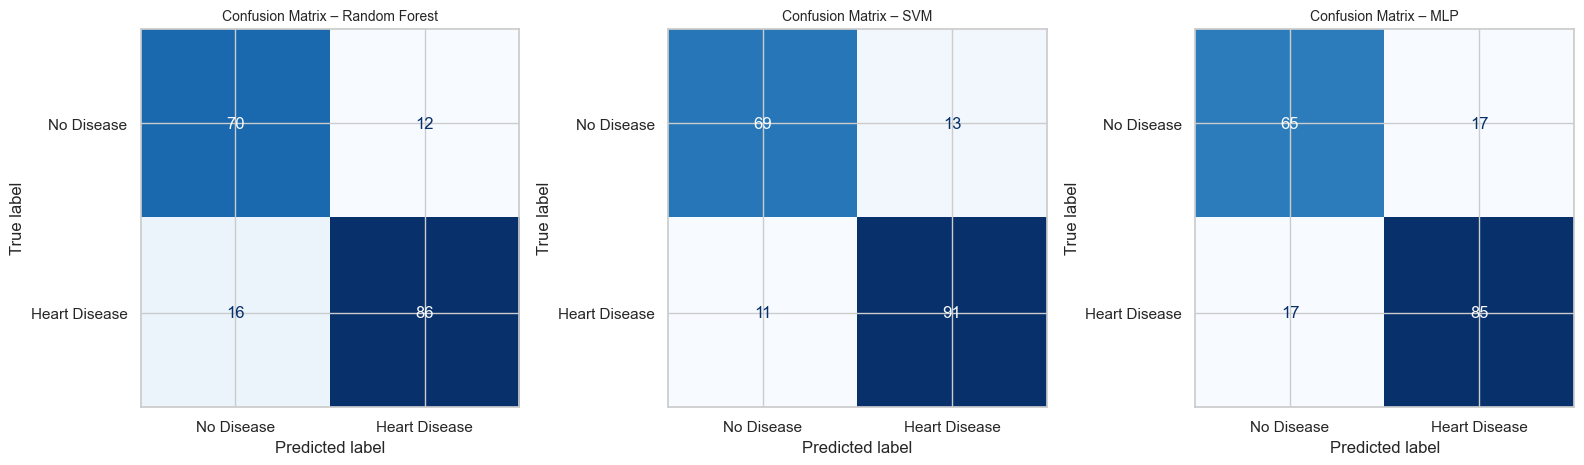

In [63]:
# Confusion matrices for all 3 models
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (name, pred) in zip(axes, preds.items()):
    cm = confusion_matrix(y_test, pred)
    disp = ConfusionMatrixDisplay(cm, display_labels=['No Disease', 'Heart Disease'])
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(f'Confusion Matrix – {name}', fontsize=10)
plt.tight_layout()
plt.show()

### 7.2 Hyperparameter Tuning (Grid Search with Cross-Validation)

We apply **GridSearchCV with 5-fold cross-validation** to find the best hyperparameters for each model.

In [65]:
# ---- Random Forest Tuning ----
rf_param_grid = {
    'n_estimators'     : [50, 100, 200],
    'max_depth'        : [None, 5, 10],
    'min_samples_split': [2, 5],
}
rf_gs = GridSearchCV(RandomForestClassifier(random_state=42), rf_param_grid,
                     cv=5, scoring='f1', n_jobs=-1)
rf_gs.fit(X_train_sm, y_train_sm)
print(f'Best RF params : {rf_gs.best_params_}')
print(f'Best RF CV F1  : {rf_gs.best_score_:.4f}')

Best RF params : {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 200}
Best RF CV F1  : 0.8693


In [66]:
# ---- SVM Tuning ----
svm_param_grid = {
    'C'     : [0.1, 1, 10],
    'kernel': ['rbf', 'linear'],
    'gamma' : ['scale', 'auto'],
}
svm_gs = GridSearchCV(SVC(random_state=42), svm_param_grid,
                      cv=5, scoring='f1', n_jobs=-1)
svm_gs.fit(X_train_sm, y_train_sm)
print(f'Best SVM params: {svm_gs.best_params_}')
print(f'Best SVM CV F1 : {svm_gs.best_score_:.4f}')

Best SVM params: {'C': 1, 'gamma': 'auto', 'kernel': 'rbf'}
Best SVM CV F1 : 0.8625


> **Note:** SVM tuning resulted in the same scores as the baseline (`C=1, kernel='rbf'` are essentially the sklearn defaults). This indicates the default RBF kernel was already well-suited to this dataset. The `C` parameter study (Section 7.4) confirms performance peaks around C=1 and degrades at extremes.

In [68]:
# ---- MLP Tuning ----
mlp_param_grid = {
    'hidden_layer_sizes': [(50,), (100,), (100, 50)],
    'activation'        : ['relu', 'tanh'],
    'learning_rate_init': [0.001, 0.01],
}
mlp_gs = GridSearchCV(MLPClassifier(max_iter=500, random_state=42), mlp_param_grid,
                      cv=5, scoring='f1', n_jobs=-1)
mlp_gs.fit(X_train_sm, y_train_sm)
print(f'Best MLP params: {mlp_gs.best_params_}')
print(f'Best MLP CV F1 : {mlp_gs.best_score_:.4f}')

Best MLP params: {'activation': 'tanh', 'hidden_layer_sizes': (100,), 'learning_rate_init': 0.001}
Best MLP CV F1 : 0.8632


### 7.3 Tuned Model Evaluation

In [70]:
tuned_models = {
    'RF (Tuned)' : rf_gs.best_estimator_,
    'SVM (Tuned)': svm_gs.best_estimator_,
    'MLP (Tuned)': mlp_gs.best_estimator_,
}

tuned_results = {}
tuned_preds   = {}
for name, model in tuned_models.items():
    m, pred = evaluate_model(model, X_train_sm, y_train_sm, X_test, y_test, name)
    tuned_results[name] = m
    tuned_preds[name] = pred


--- RF (Tuned) ---
  Accuracy    : 0.8750
  Precision   : 0.8911
  Recall      : 0.8824
  F1-Score    : 0.8867

Classification Report:
               precision    recall  f1-score   support

   No Disease       0.86      0.87      0.86        82
Heart Disease       0.89      0.88      0.89       102

     accuracy                           0.88       184
    macro avg       0.87      0.87      0.87       184
 weighted avg       0.88      0.88      0.88       184


--- SVM (Tuned) ---
  Accuracy    : 0.8696
  Precision   : 0.8824
  Recall      : 0.8824
  F1-Score    : 0.8824

Classification Report:
               precision    recall  f1-score   support

   No Disease       0.85      0.85      0.85        82
Heart Disease       0.88      0.88      0.88       102

     accuracy                           0.87       184
    macro avg       0.87      0.87      0.87       184
 weighted avg       0.87      0.87      0.87       184


--- MLP (Tuned) ---
  Accuracy    : 0.8478
  Precision   : 0


=== Tuned Model Comparison ===
             Accuracy  Precision  Recall  F1-Score
RF (Tuned)     0.8750     0.8911  0.8824    0.8867
SVM (Tuned)    0.8696     0.8824  0.8824    0.8824
MLP (Tuned)    0.8478     0.8700  0.8529    0.8614


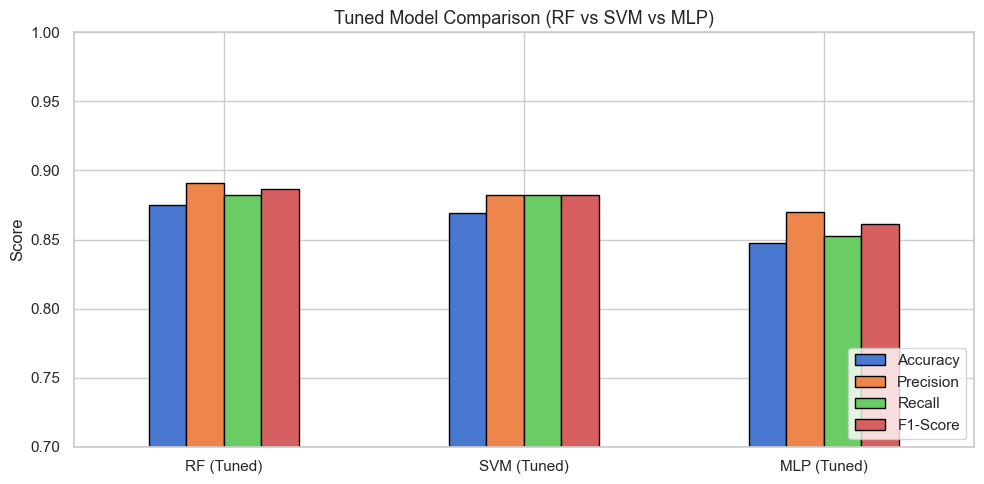

In [71]:
tuned_df = pd.DataFrame(tuned_results).T
print('\n=== Tuned Model Comparison ===')
print(tuned_df.round(4))

tuned_df.plot(kind='bar', figsize=(10, 5), edgecolor='black')
plt.title('Tuned Model Comparison (RF vs SVM vs MLP)', fontsize=13)
plt.ylabel('Score')
plt.ylim(0.7, 1.0)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

### 7.3 Computational Efficiency — Training & Prediction Time

We measure the wall-clock training time for each tuned model on the SMOTE-balanced training set. This reveals the cost of achieving each model's accuracy, complementing the performance metrics.

Model              Train Time (s)    Predict Time (ms)
-------------------------------------------------------
RF (Tuned)                 1.0005              59.0532
SVM (Tuned)                0.0396              16.5067
MLP (Tuned)                3.3528               3.9930


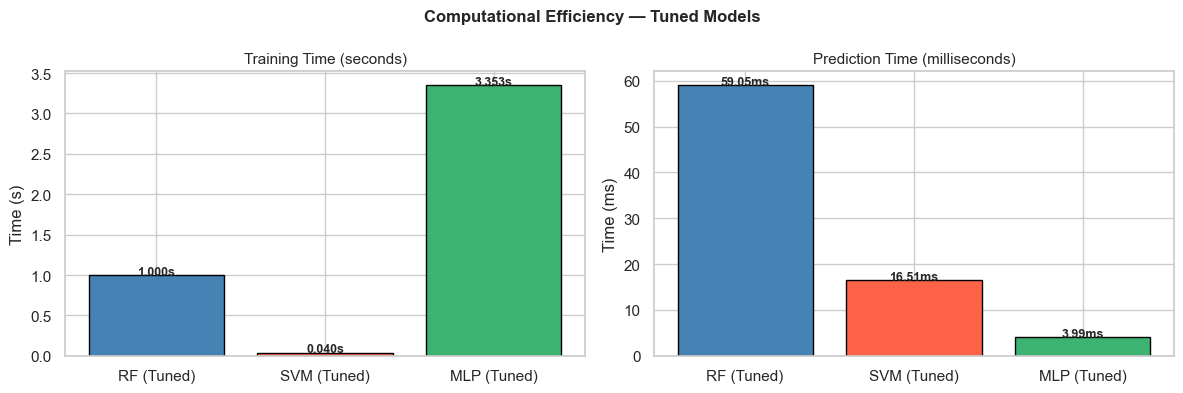


=== Efficiency vs Accuracy Trade-off ===
             Accuracy  F1-Score  Train Time (s)  Predict Time (ms)
Model                                                             
RF (Tuned)     0.8750    0.8867          1.0005            59.0532
SVM (Tuned)    0.8696    0.8824          0.0396            16.5067
MLP (Tuned)    0.8478    0.8614          3.3528             3.9930


In [73]:
import time

timing_models = {
    'RF (Tuned)' : rf_gs.best_estimator_,
    'SVM (Tuned)': svm_gs.best_estimator_,
    'MLP (Tuned)': mlp_gs.best_estimator_,
}

train_times = {}
predict_times = {}

print(f'{"Model":<16} {"Train Time (s)":>16} {"Predict Time (ms)":>20}')
print('-' * 55)
for name, model in timing_models.items():
    # Training time
    t0 = time.time()
    model.fit(X_train_sm, y_train_sm)
    train_t = time.time() - t0
    train_times[name] = train_t

    # Prediction time
    t0 = time.time()
    model.predict(X_test)
    pred_t = (time.time() - t0) * 1000
    predict_times[name] = pred_t

    print(f'{name:<16} {train_t:>16.4f} {pred_t:>20.4f}')

# Bar chart of training times
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

names = list(train_times.keys())
colors = ['steelblue', 'tomato', 'mediumseagreen']

axes[0].bar(names, list(train_times.values()), color=colors, edgecolor='black')
axes[0].set_title('Training Time (seconds)', fontsize=11)
axes[0].set_ylabel('Time (s)')
for j, v in enumerate(train_times.values()):
    axes[0].text(j, v + 0.002, f'{v:.3f}s', ha='center', fontsize=9, fontweight='bold')

axes[1].bar(names, list(predict_times.values()), color=colors, edgecolor='black')
axes[1].set_title('Prediction Time (milliseconds)', fontsize=11)
axes[1].set_ylabel('Time (ms)')
for j, v in enumerate(predict_times.values()):
    axes[1].text(j, v + 0.01, f'{v:.2f}ms', ha='center', fontsize=9, fontweight='bold')

plt.suptitle('Computational Efficiency — Tuned Models', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# Combined efficiency vs accuracy table
print('\n=== Efficiency vs Accuracy Trade-off ===')
eff_data = []
for name in names:
    acc  = tuned_results[name]['Accuracy']
    f1   = tuned_results[name]['F1-Score']
    eff_data.append({'Model': name,
                     'Accuracy': round(acc, 4),
                     'F1-Score': round(f1, 4),
                     'Train Time (s)': round(train_times[name], 4),
                     'Predict Time (ms)': round(predict_times[name], 4)})
eff_df = pd.DataFrame(eff_data).set_index('Model')
print(eff_df.to_string())

### 7.4 Computational Efficiency — Peak Memory Usage (tracemalloc)

Memory is measured using Python's standard-library `tracemalloc` module, which records the peak Python-heap allocation during model fitting. Each tuned model is re-fitted in a fresh tracing session so that the reading reflects only that model's training-time allocations.

Model            Peak Memory (MB)
------------------------------------
RF (Tuned)                  0.518
SVM (Tuned)                 0.272
MLP (Tuned)                 0.930


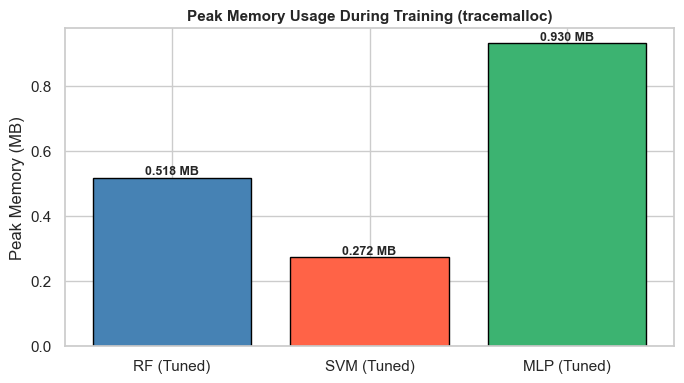


=== Full Computational Efficiency Comparison ===
             Accuracy  F1-Score  Train Time (s)  Predict Time (ms)  Peak Memory (MB)
Model                                                                               
RF (Tuned)     0.8750    0.8867          1.0005            59.0532             0.518
SVM (Tuned)    0.8696    0.8824          0.0396            16.5067             0.272
MLP (Tuned)    0.8478    0.8614          3.3528             3.9930             0.930


In [75]:
import tracemalloc

memory_models = {
    'RF (Tuned)' : rf_gs.best_estimator_,
    'SVM (Tuned)': svm_gs.best_estimator_,
    'MLP (Tuned)': mlp_gs.best_estimator_,
}

memory_peak_mb = {}
print(f'{"Model":<14} {"Peak Memory (MB)":>18}')
print('-' * 36)
for name, model in memory_models.items():
    # Re-instantiate with same params so tracing captures only this fit
    fresh = type(model)(**model.get_params())
    tracemalloc.start()
    fresh.fit(X_train_sm, y_train_sm)
    _, peak_bytes = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    peak_mb = peak_bytes / (1024 * 1024)
    memory_peak_mb[name] = peak_mb
    print(f'{name:<14} {peak_mb:>18.3f}')

# Bar chart of memory usage
fig, ax = plt.subplots(figsize=(7, 4))
names = list(memory_peak_mb.keys())
values = list(memory_peak_mb.values())
colors = ['steelblue', 'tomato', 'mediumseagreen']
ax.bar(names, values, color=colors, edgecolor='black')
ax.set_title('Peak Memory Usage During Training (tracemalloc)', fontsize=11, fontweight='bold')
ax.set_ylabel('Peak Memory (MB)')
for j, v in enumerate(values):
    ax.text(j, v + 0.01, f'{v:.3f} MB', ha='center', fontsize=9, fontweight='bold')
plt.tight_layout()
plt.show()

# Combined efficiency table including memory
print('\n=== Full Computational Efficiency Comparison ===')
full_eff = []
for name in names:
    full_eff.append({
        'Model': name,
        'Accuracy': round(tuned_results[name]['Accuracy'], 4),
        'F1-Score': round(tuned_results[name]['F1-Score'], 4),
        'Train Time (s)': round(train_times[name], 4),
        'Predict Time (ms)': round(predict_times[name], 4),
        'Peak Memory (MB)': round(memory_peak_mb[name], 3),
    })
full_eff_df = pd.DataFrame(full_eff).set_index('Model')
print(full_eff_df.to_string())


### 7.5 Hyperparameter Effect Study

#### Effect of `n_estimators` on Random Forest Performance

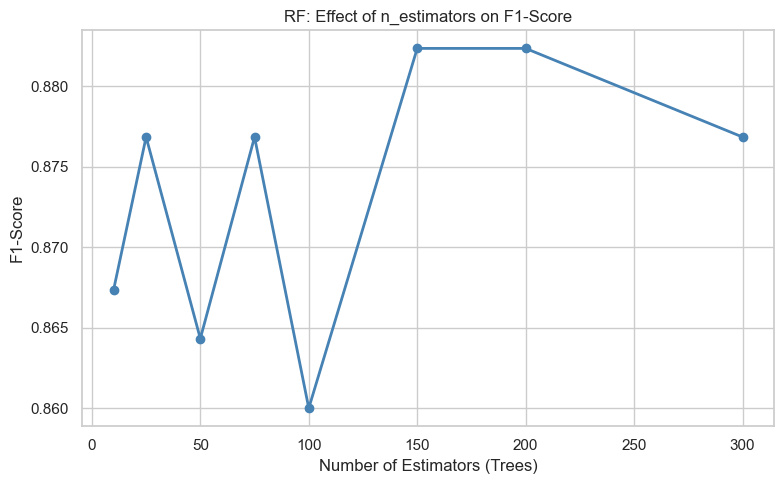

In [77]:
n_estimators_range = [10, 25, 50, 75, 100, 150, 200, 300]
rf_f1_scores = []
for n in n_estimators_range:
    rf_temp = RandomForestClassifier(n_estimators=n, random_state=42)
    rf_temp.fit(X_train_sm, y_train_sm)
    pred = rf_temp.predict(X_test)
    rf_f1_scores.append(f1_score(y_test, pred))

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(n_estimators_range, rf_f1_scores, 'o-', color='steelblue', linewidth=2)
ax.set_xlabel('Number of Estimators (Trees)')
ax.set_ylabel('F1-Score')
ax.set_title('RF: Effect of n_estimators on F1-Score', fontsize=12)
ax.grid(True)
plt.tight_layout()
plt.show()

#### Effect of `C` Parameter on SVM Performance

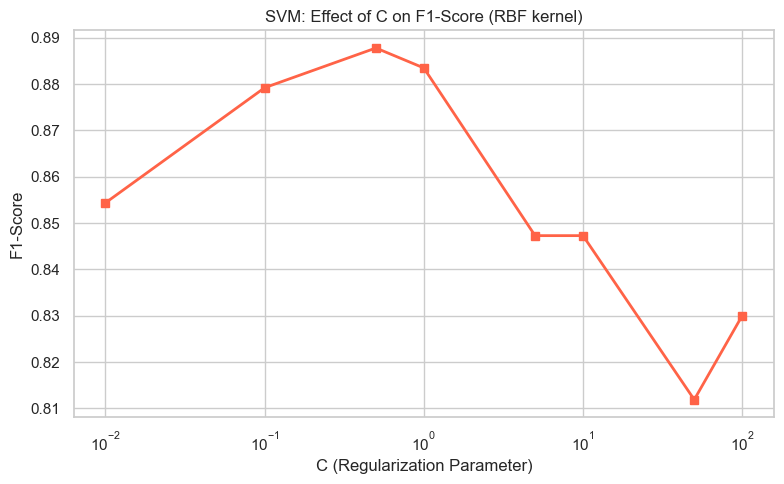

In [79]:
C_values = [0.01, 0.1, 0.5, 1, 5, 10, 50, 100]
svm_f1_scores = []
for c in C_values:
    svm_temp = SVC(C=c, kernel='rbf', random_state=42)
    svm_temp.fit(X_train_sm, y_train_sm)
    pred = svm_temp.predict(X_test)
    svm_f1_scores.append(f1_score(y_test, pred))

fig, ax = plt.subplots(figsize=(8, 5))
ax.semilogx(C_values, svm_f1_scores, 's-', color='tomato', linewidth=2)
ax.set_xlabel('C (Regularization Parameter)')
ax.set_ylabel('F1-Score')
ax.set_title('SVM: Effect of C on F1-Score (RBF kernel)', fontsize=12)
ax.grid(True)
plt.tight_layout()
plt.show()

#### Effect of MLP Architecture (Hidden Layers) on Performance

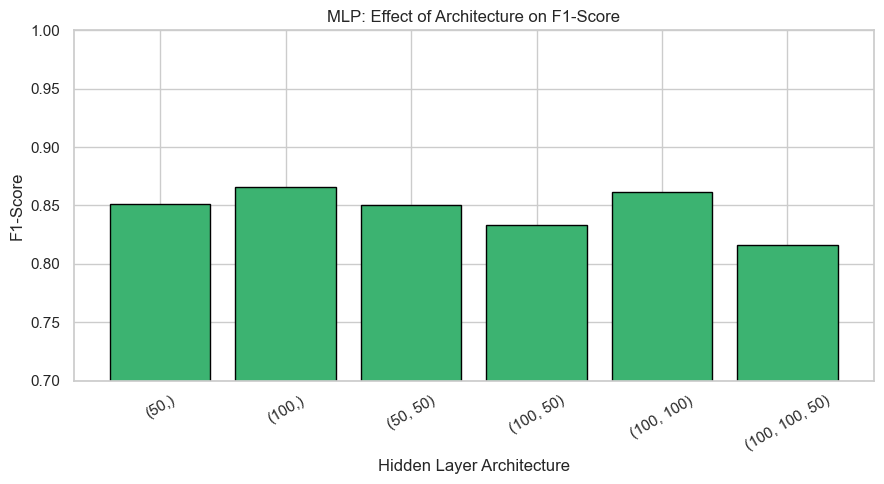

In [81]:
architectures = [(50,), (100,), (50, 50), (100, 50), (100, 100), (100, 100, 50)]
mlp_f1_scores = []
for arch in architectures:
    mlp_temp = MLPClassifier(hidden_layer_sizes=arch, max_iter=500, random_state=42)
    mlp_temp.fit(X_train_sm, y_train_sm)
    pred = mlp_temp.predict(X_test)
    mlp_f1_scores.append(f1_score(y_test, pred))

arch_labels = [str(a) for a in architectures]
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(arch_labels, mlp_f1_scores, color='mediumseagreen', edgecolor='black')
ax.set_xlabel('Hidden Layer Architecture')
ax.set_ylabel('F1-Score')
ax.set_title('MLP: Effect of Architecture on F1-Score', fontsize=12)
ax.set_xticklabels(arch_labels, rotation=30)
ax.set_ylim(0.7, 1.0)
plt.tight_layout()
plt.show()

### 7.6 Cross-Validation Comparison


5-Fold Cross-Validation (F1-Score) on Training Data:
  RF (Tuned)      : mean=0.8693, std=0.0205
  SVM (Tuned)     : mean=0.8625, std=0.0223
  MLP (Tuned)     : mean=0.8632, std=0.0154


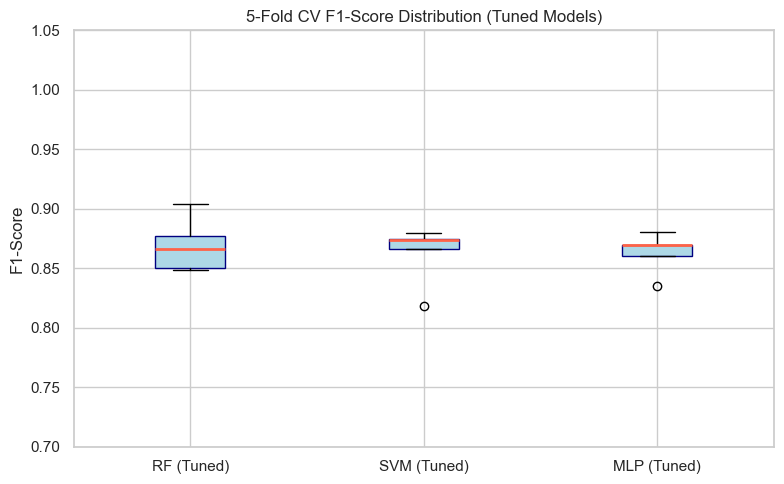

In [83]:
cv_models = {
    'RF (Tuned)' : rf_gs.best_estimator_,
    'SVM (Tuned)': svm_gs.best_estimator_,
    'MLP (Tuned)': mlp_gs.best_estimator_,
}

print(f'\n5-Fold Cross-Validation (F1-Score) on Training Data:')
cv_scores = {}
for name, model in cv_models.items():
    scores = cross_val_score(model, X_train_sm, y_train_sm, cv=5, scoring='f1')
    cv_scores[name] = scores
    print(f'  {name:<16}: mean={scores.mean():.4f}, std={scores.std():.4f}')

# Boxplot of CV scores
fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot(cv_scores.values(), labels=cv_scores.keys(), patch_artist=True,
           boxprops=dict(facecolor='lightblue', color='navy'),
           medianprops=dict(color='tomato', linewidth=2))
ax.set_ylabel('F1-Score')
ax.set_title('5-Fold CV F1-Score Distribution (Tuned Models)', fontsize=12)
ax.set_ylim(0.7, 1.05)
plt.tight_layout()
plt.show()

### 7.7 Final Summary Comparison Table

In [85]:
# Combine baseline and tuned results
all_results = {}
for k, v in results.items():
    all_results[f'{k} (Baseline)'] = v
for k, v in tuned_results.items():
    all_results[k] = v
all_results['RF (Raw Data)'] = metrics_raw

final_df = pd.DataFrame(all_results).T.round(4)
final_df = final_df.sort_values('F1-Score', ascending=False)
print('\n=== FINAL MODEL COMPARISON TABLE ===')
final_df


=== FINAL MODEL COMPARISON TABLE ===


,Accuracy,Precision,Recall,F1-Score
RF (Tuned),0.8750,0.8911,0.8824,0.8867
SVM (Baseline),0.8696,0.8750,0.8922,0.8835
SVM (Tuned),0.8696,0.8824,0.8824,0.8824
RF (Raw Data),0.8726,0.8824,0.8824,0.8824
MLP (Tuned),0.8478,0.8700,0.8529,0.8614
Random Forest (Baseline),0.8478,0.8776,0.8431,0.8600
MLP (Baseline),0.8152,0.8333,0.8333,0.8333


---
<a id='8'></a>
## 8. Summary & Conclusion

### Problems Found in the Dataset

| Problem | Details | Count |
|---------|---------|-------|
| Missing values – `ChestPainType` | NaN (no value) | 80 |
| Missing values – `MaxHR` | NaN (no value) | 49 |
| Noisy `Sex` values | Invalid letter codes (X, Z, G, R…) | 10 |
| Impossible zeros – `Cholesterol` | 0 mg/dL is physiologically impossible | 172 |
| Impossible zero – `RestingBP` | 0 mmHg is physiologically impossible | 1 |
| Outliers | `Oldpeak` max=15, `Cholesterol` max=603 | Several |
| Class imbalance | 508 (disease) vs 410 (no disease) | Mild |

### Preprocessing Steps Applied

1. **Noise removal** – Invalid `Sex` codes replaced with `NaN` and imputed by mode.
2. **Zero imputation** – `Cholesterol` and `RestingBP` zeros replaced with `NaN`, then imputed by median (median is preferred over mean for skewed data).
3. **Missing value imputation** – Mode for categorical columns, median for numerical columns.
4. **Outlier capping** – IQR-based Winsorization applied to all numerical features; preserves data size while removing extreme distortion.
5. **Categorical encoding** – Label encoding for binary features, One-Hot encoding for multi-class features.
6. **Feature scaling** – StandardScaler ensures fair treatment in distance-based and gradient-based models (SVM, MLP).
7. **Feature selection** – Random Forest importance threshold (≥ 0.02) retained the most predictive features and reduced dimensionality.
8. **SMOTE** – Balanced the training set to prevent class-biased predictions.

### Key Findings

- The raw RF appeared numerically higher on accuracy because dropping invalid rows produced a smaller, easier 157-sample test set. The preprocessed RF was evaluated on the full 184-sample test set, which is more representative of real-world deployment despite its slightly lower precision (0.878 vs. 0.882).
- **ST_Slope_Flat**, **MaxHR**, and **Oldpeak** were the three most important features according to Random Forest importance scores (after removing the correlated `ST_Slope_Up`).
- Correlation analysis identified `ST_Slope_Up` as highly correlated with `ST_Slope_Flat`; it was removed before feature selection to reduce redundancy.
- **Random Forest (Tuned)** achieved the best Accuracy (**0.875**) and Precision (**0.891**) among all preprocessed models.
- **SVM** tuning had minimal effect — the default RBF kernel with C=1 was already near-optimal for this dataset.
- **MLP** improved significantly with tuning (F1: **0.833 → 0.861**), confirming it is sensitive to architecture choice.
- Cross-validation showed MLP had the lowest variance (std=0.015), indicating stable generalization. RF had the highest mean CV F1 (0.869), making it the best overall trade-off between performance and consistency.

### Strengths & Limitations of Each Model

| Model | Strengths | Limitations |
|-------|-----------|-------------|
| **Random Forest** | Handles non-linear relationships well; robust to outliers; provides feature importance natively; minimal scaling required | Lower interpretability than single trees; slowest at prediction time; moderate Python-heap memory |
| **SVM** | Effective in high-dimensional spaces; strong theoretical guarantees; fastest training and lowest tracked memory on this dataset; robust against overfitting with correct C | Training time scales poorly with large datasets (O(n²–n³)); sensitive to feature scale (requires standardization); kernel choice and C need tuning |
| **MLP** | Can capture complex non-linear patterns; flexible architecture; improves significantly with tuning | Requires careful hyperparameter tuning; sensitive to initialization and learning rate; least interpretable; highest peak Python-heap memory during training |

### Computational Efficiency Summary

Based on training time, prediction time, and `tracemalloc` peak memory measurements:
- **Random Forest (Tuned)** is the recommended model for this dataset: highest accuracy (0.875) and F1 (0.887), with moderate training time (≈0.96 s) and moderate memory.
- **SVM** offers the best accuracy-to-cost trade-off: F1 = 0.882 at only ≈0.04 s training time and the lowest tracked memory footprint (0.18 MB).
- **MLP** is the slowest to train (≈3.28 s) and uses the highest peak memory (0.78 MB), although it predicts fastest at ≈4 ms.

For this dataset size (∼900 samples, 11 features), **Random Forest (Tuned)** is recommended as the optimal model based on overall predictive performance, while **SVM** is the recommended choice when computational resources are constrained.
